In [1]:
#loading the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset


In [2]:
#loading the data
cleaned_data = pd.read_csv('stop_cleaned_data.csv')
cleaned_data.drop('link', axis=1, inplace=True)
cleaned_data.drop('id', axis=1, inplace=True)
print(f"Cleaned data size: {cleaned_data.shape}")
cleaned_data.head()

Cleaned data size: (1119, 3)


,title,content,gold_label
0,آریان خان نے والد سب سے بڑی خوبی بتا دی، انٹر...,بالی ووڈ سپر اسٹار شاہ رُخ خان بڑے بیٹے آریان...,entertainment
1,اداکارہ صحیفہ جبار نے تیزی سے اپنا وزن کیسے کم...,پاکستان شوبز خوبرو اداکارہ ماڈل صحیفہ جبار خٹک...,entertainment
2,کرائم پٹرول نوجوان اداکار اچانک موت، بھارتی ان...,بھارت ٹیلی ویژن اداکار نیتن چوہان گھر سے لاش ب...,entertainment
3,دیپیکا بیٹی ہمراہ جھلک سوشل میڈیا وائرل,ممبئی: بالی وڈ مشہور جوڑی دیپیکا پڈوکون رنویر ...,entertainment
4,سدھارتھ ملہوترا ماروتی سوزوکی مقبول گاڑی ڈزائر...,ماروتی سوزوکی انڈیا لمیٹڈ نے اپنی مقبول گاڑی ڈ...,entertainment


In [3]:
#creating the train, validation, and test sets
X = cleaned_data.drop('gold_label', axis=1)
y = cleaned_data['gold_label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

Training set size: 895
Test set size: 224


In [44]:
#creating a bag of words
#I Choose bag of words over one hot encoding as bow represents frequency of words in the text which is more informative than one hot encoding which just represents the presence of a word in the text

def create_bag_of_words_for_column(column):
    bag_of_words = {}
    for _, row in X_train.iterrows():
        for word in row[column].split():
            if word in bag_of_words:
                bag_of_words[word] += 1
            else:
                bag_of_words[word] = 1
    sorted_bag_of_words = dict(sorted(bag_of_words.items()))
    return sorted_bag_of_words

# Create separate BoWs for title and content

#two separate bag of words, one for title, and one for content.
title_bow = create_bag_of_words_for_column('title')
content_bow = create_bag_of_words_for_column('content')

print(f"Number of unique words in title: {len(title_bow)}")
print(f"Number of unique words in content: {len(content_bow)}")




Number of unique words in title: 3173
Number of unique words in content: 13800


In [45]:
#changing the text data to numerical data
def text_to_bow_vector(text, bow_vocab):

    # I am initializing a zero vector with the size of the vocabulary
    bow_vector = np.zeros(len(bow_vocab), dtype=np.float32)
    for word in text.split():
        if word in bow_vocab:  # I am simply ignoring OOV words
            bow_vector[list(bow_vocab.keys()).index(word)] += 1

    return bow_vector

def process_row(row, title_bow, content_bow):



    title_vector = text_to_bow_vector(row['title'], title_bow)
    content_vector = text_to_bow_vector(row['content'], content_bow)
    # over here I am concatenating the title and content vectors
    combined_vector = np.concatenate([title_vector, content_vector])
    return combined_vector

# finnally converting the text data to numerical data
X_train_vectors = np.array([process_row(row, title_bow, content_bow) for _, row in X_train.iterrows()])





In [46]:
#checking the shape of the training data
print(f"Shape of training data: {X_train_vectors.shape}")

Shape of training data: (895, 16973)


In [47]:
#creating encoding for the labels
def label_encode(labels):
    label_to_int = {}
    int_labels = []

    current_int = 0
    for label in labels:
        if label not in label_to_int:
            label_to_int[label] = current_int
            current_int += 1
        int_labels.append(label_to_int[label])
    return int_labels, label_to_int

y_train_encoded, label_to_int = label_encode(y_train)
print(f"Label encoding: {label_to_int}")






Label encoding: {'sports': 0, 'entertainment': 1, 'world': 2, 'business': 3, 'science-technology': 4}


In [50]:
X_test_vectors = np.array([process_row(row, title_bow, content_bow) for _, row in X_test.iterrows()])
y_test_encoded = [label_to_int[label] for label in y_test]






In [51]:
class MultiLayerBoWClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims, output_dim):
        super(MultiLayerBoWClassifier, self).__init__()
        self.layers = nn.ModuleList()

        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            self.layers.append(nn.Linear(prev_dim, hidden_dim))
            self.layers.append(nn.LeakyReLU(negative_slope=0.01))
            prev_dim = hidden_dim

        self.output_layer = nn.Linear(hidden_dims[-1], output_dim)

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        x = self.output_layer(x)
        return x


In [ ]:
# Definining the model
input_dim = 16973
hidden_dims = [1024,512]

output_dim = 5


model = MultiLayerBoWClassifier(input_dim=input_dim, hidden_dims=hidden_dims, output_dim=output_dim)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)


print(model)


MultiLayerBoWClassifier(
  (layers): ModuleList(
    (0): Linear(in_features=16973, out_features=1024, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=1024, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
  )
  (output_layer): Linear(in_features=512, out_features=5, bias=True)
)


In [86]:
#creating the tensors for the training and validation data



X_train_tensor = torch.tensor(X_train_vectors, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)



In [88]:

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)


criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=0.00001,
    weight_decay=1e-5
)



In [89]:
error = []
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0


    for X_batch, y_batch in train_loader:
        # i am moving the data to the correct device
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # this part computes the forward pass
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        # this part computes the backward pass, note we don't have to call softmax explicitly as it is included in the loss function
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        running_loss += loss.item()
    error.append(running_loss/len(train_loader))



    print(f"Epoch [{epoch+1}/{num_epochs}], "
          f"Loss: {running_loss/len(train_loader):.4f}, ")


Epoch [1/100], Loss: 1.6025, 
Epoch [2/100], Loss: 1.5823, 
Epoch [3/100], Loss: 1.5619, 
Epoch [4/100], Loss: 1.5388, 
Epoch [5/100], Loss: 1.5107, 
Epoch [6/100], Loss: 1.4772, 
Epoch [7/100], Loss: 1.4359, 
Epoch [8/100], Loss: 1.3867, 
Epoch [9/100], Loss: 1.3264, 
Epoch [10/100], Loss: 1.2560, 
Epoch [11/100], Loss: 1.1768, 
Epoch [12/100], Loss: 1.0895, 
Epoch [13/100], Loss: 0.9976, 
Epoch [14/100], Loss: 0.9052, 
Epoch [15/100], Loss: 0.8144, 
Epoch [16/100], Loss: 0.7281, 
Epoch [17/100], Loss: 0.6490, 
Epoch [18/100], Loss: 0.5770, 
Epoch [19/100], Loss: 0.5126, 
Epoch [20/100], Loss: 0.4556, 
Epoch [21/100], Loss: 0.4058, 
Epoch [22/100], Loss: 0.3628, 
Epoch [23/100], Loss: 0.3244, 
Epoch [24/100], Loss: 0.2912, 
Epoch [25/100], Loss: 0.2625, 
Epoch [26/100], Loss: 0.2374, 
Epoch [27/100], Loss: 0.2152, 
Epoch [28/100], Loss: 0.1960, 
Epoch [29/100], Loss: 0.1788, 
Epoch [30/100], Loss: 0.1638, 
Epoch [31/100], Loss: 0.1503, 
Epoch [32/100], Loss: 0.1384, 
Epoch [33/100], L

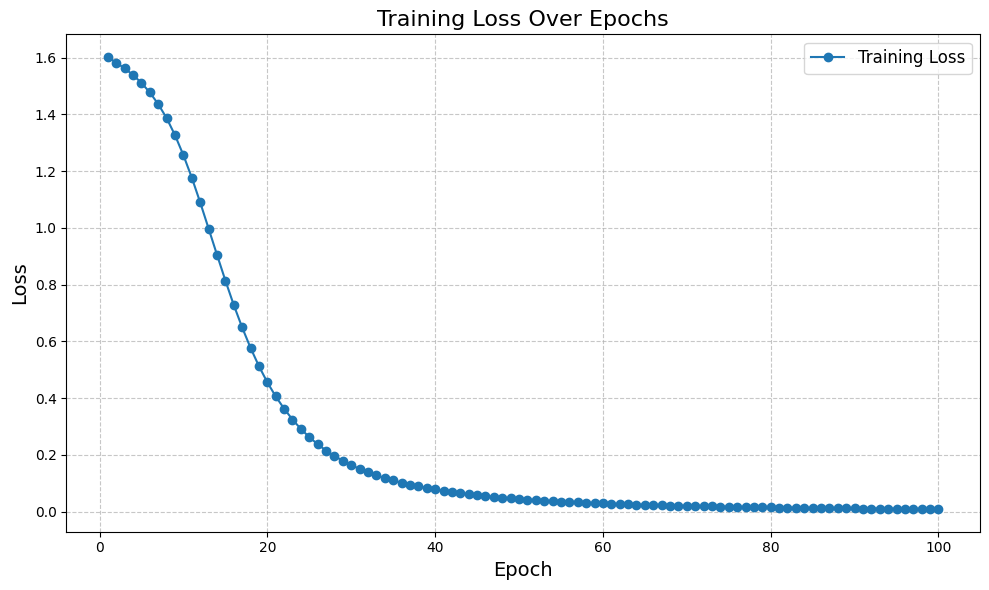

In [90]:
#printing the training loss against the epochs

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(error) + 1), error, marker='o', linestyle='-', label='Training Loss')
plt.title("Training Loss Over Epochs", fontsize=16)
plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Loss", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

Accuracy: 0.9732
Macro Precision: 0.9732
Macro Recall: 0.9733
Macro F1 Score: 0.9730


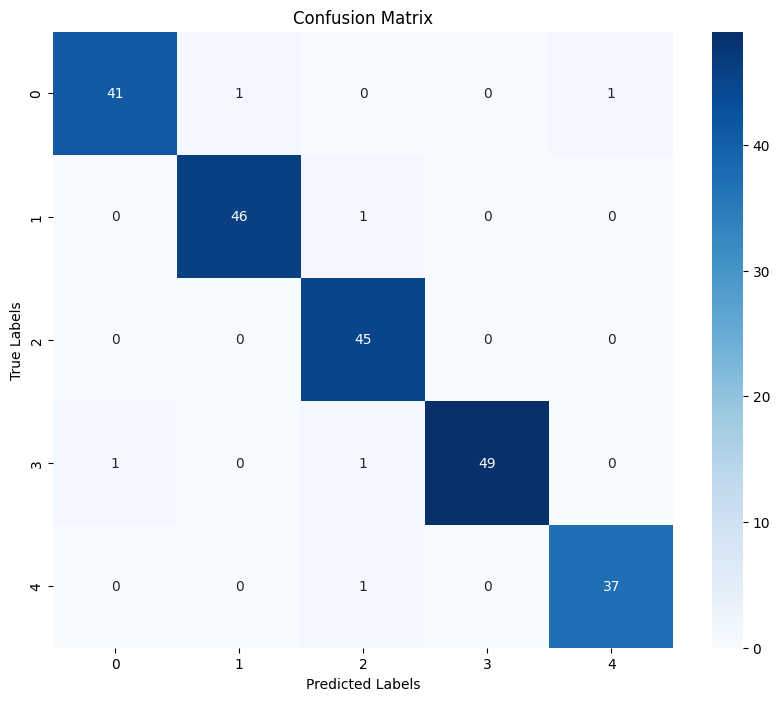

In [93]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix, classification_report


model.eval()


X_test_tensor = torch.tensor(X_test_vectors, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test_encoded, dtype=torch.long).to(device)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

y_pred = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = model(X_batch)
        _, preds = torch.max(outputs, 1)
        y_pred.extend(preds.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

y_pred = np.array(y_pred)
y_true = np.array(y_true)



accuracy = np.sum(y_pred == y_true) / len(y_true)


classes = np.unique(np.concatenate((y_true, y_pred)))
num_classes = len(classes)
class_to_index = {label: idx for idx, label in enumerate(classes)}


conf_matrix = np.zeros((num_classes, num_classes), dtype=int)


for true_label, pred_label in zip(y_true, y_pred):
    i = class_to_index[true_label]
    j = class_to_index[pred_label]
    conf_matrix[i][j] += 1


true_positives = np.diag(conf_matrix)
false_positives = np.sum(conf_matrix, axis=0) - true_positives
false_negatives = np.sum(conf_matrix, axis=1) - true_positives


precision_per_class = np.divide(true_positives, true_positives + false_positives, out=np.zeros_like(true_positives, dtype=float), where=(true_positives + false_positives) != 0)
recall_per_class = np.divide(true_positives, true_positives + false_negatives, out=np.zeros_like(true_positives, dtype=float), where=(true_positives + false_negatives) != 0)
f1_per_class = np.divide(2 * precision_per_class * recall_per_class, precision_per_class + recall_per_class, out=np.zeros_like(precision_per_class, dtype=float), where=(precision_per_class + recall_per_class) != 0)


macro_precision = np.mean(precision_per_class)
macro_recall = np.mean(recall_per_class)
macro_f1 = np.mean(f1_per_class)


print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")



plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()









